Tieu Han TRAN - M2 MIAGE

# Statistical and Machine Learning
# Homework 1 : Introduction and Learnability

## Learning problem
* **Input space :** $\mathcal{X} = [0, 1]$ muni d'une distribution uniforme
* **Target function :** unknown threshold classifier (classifieur à seuil inconnu) $f_\theta(x) = \mathbb{1}\{x > \theta\}$, où $\theta \in (0, 1)$ est fixé.
* **Labels :** $y = f_\theta(x)$
* **Agnostic setting :** si on est dans APAC, alors les étiquettes peuvent être inversées avec la probabilité de $\eta$.

## 1. Data Generation
On génère des training datasets $S = \{(x_i, y_i)\}_{i=1}^m$ de différentes tailles $m \in \{5, 10, 20, 50, 100, 200\}$.
On choisit le seuil à $\theta = 0.4$. Si on est dans le cadre PAC où on a l'hypothèse de réalisabilité (Realizability Assumption) alors $\eta = 0$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Fixer le point de départ (seed) pour reproduire les expériences et avoir les mêmes résultats pour les interprétations
np.random.seed(0)

# Paramètres globaux de l'expérience
THETA = 0.4  # Seuil \theta \in (0, 1)
m_tab = [5, 10, 20, 50, 100, 200]  # tailles des échantillons

def fonction_cible(x, theta=THETA):
  """Calcule le résultat de la fonction cible f_theta(x).
  Renvoie 1 si x > theta, 0 sinon.
  """
  res = np.where(x > theta, 1, 0)
  return res

def generer_dataset(m, theta=THETA, eta=0.0):
  """Génère un training dataset S de taille m.
  Entrées :
  - m (int) : Nombre d'exemples dans le training set
  - theta (float) : la limite theta dans (0, 1).
  - eta (float) : la probabilité que l'étiquette soit inversée dans le cadre APAC :
                  eta = 0.0 correspond au cadre PAC.
                  eta > 0.0 correspond au cadre Agnostic PAC.
  Retourne :
  - x_tab (np.ndarray) : Tableau 1D d'instances x tirées uniformément dans [0, 1].
  - y_tab (np.ndarray) : Tableau 1D d'étiquettes y dans {0, 1} associés aux instances x de x_tab.
  """
  # 1. Tirage uniforme des instances x dans X = [0, 1] m fois
  x_tab = np.random.uniform(0.0, 1.0, size=m)

  # 2. Génération des étiquettes selon la fonction cible y = f_theta(x)
  y_tab = fonction_cible(x_tab, theta)

  # 3. Lorsque APAC donc lorsqu'on n'a pas l'hypothèse de réalisabilité : inversion indépendante de chaque étiquette avec probabilité eta
  if eta > 0.0:
    inverser_tab = np.random.uniform(0.0, 1.0, size=m) < eta #Génère aléatoirement selon eta le tableau qui contient true s'il faut inverser l'étiquette de l'instance x donnée, false sinon"
    y_tab = np.where(inverser_tab, 1 - y_tab, y_tab) #Modifie les étiquettes associées aux instances selon le tableau inverser_tab"
  return x_tab, y_tab

# Génération des datasets pour toutes les tailles m dans le cadre PAC (avec l'hypothèse de réalisabilité) : eta = 0.0
datasets = {}
for m in m_tab:
    datasets[m] = generer_dataset(m, theta=THETA, eta=0.0)

print(
    "Training datasets générés avec succès pour m appartenant à :",
    list(datasets.keys()),
)

Training datasets générés avec succès pour m appartenant à : [5, 10, 20, 50, 100, 200]


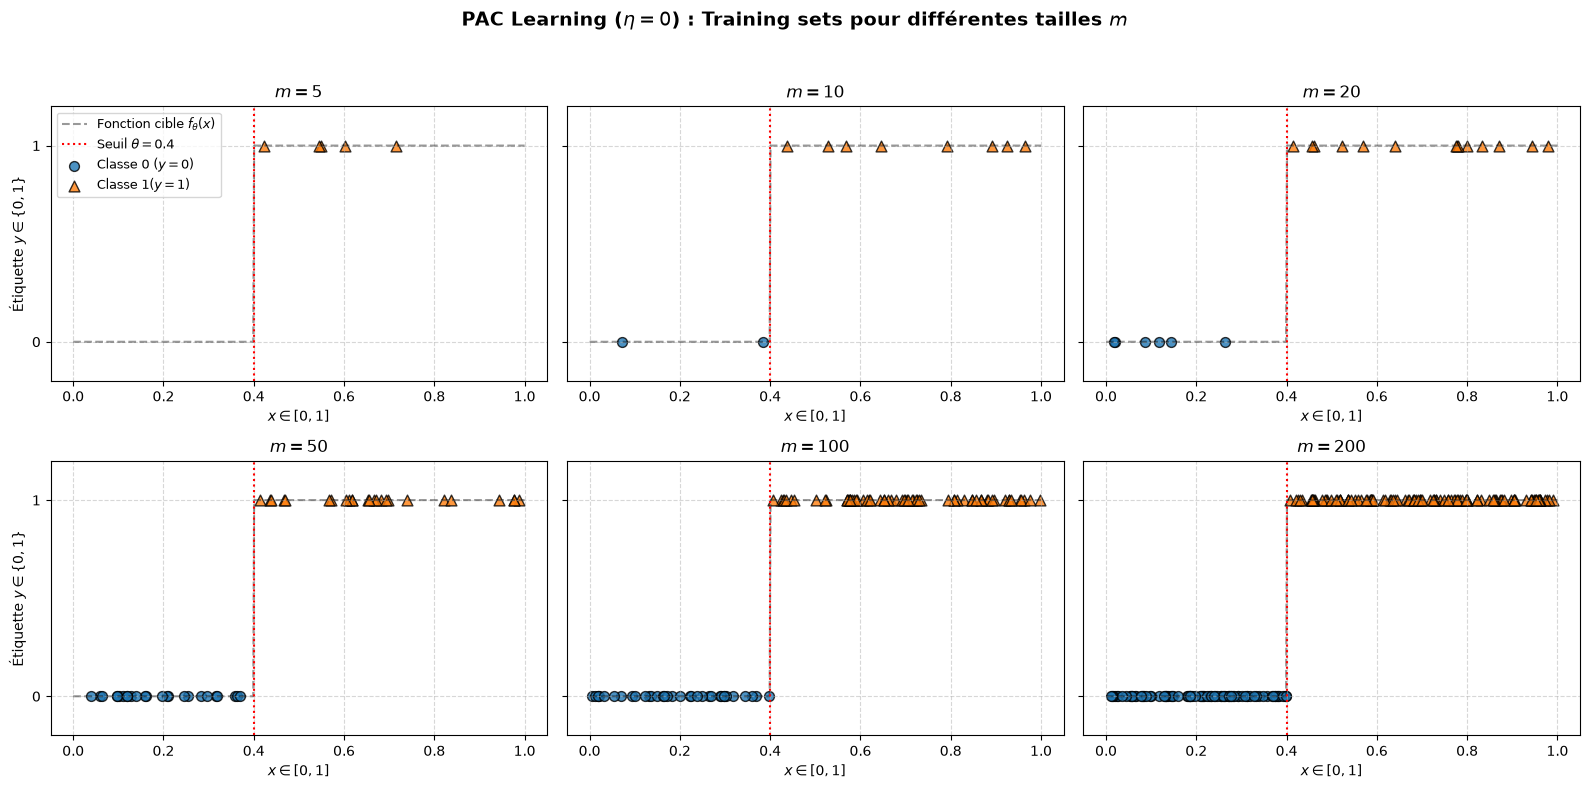

In [2]:
# Visualisation des training set générés pour les différentes tailles m
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
axes = axes.flatten()

x_grille = np.linspace(0, 1, 500)
y_courbe = fonction_cible(x_grille, THETA)

for idx, m in enumerate(m_tab):
  ax = axes[idx]
  x_ech, y_ech = datasets[m]

  # Tracé de la fonction cible en escalier f_theta(x)
  ax.plot(
      x_grille,
      y_courbe,
      color='black',
      linestyle='--',
      alpha=0.4,
      label=r'Fonction cible $f_\theta(x)$',
  )

  # Tracé de la ligne verticale représentant la seuil theta
  ax.axvline(
      x=THETA,
      color='red',
      linestyle=':',
      linewidth=1.5,
      label=rf'Seuil $\theta={THETA}$',
  )

  # Séparation des classes pour une visualisation claire
  x_classe0 = x_ech[y_ech == 0]
  x_classe1 = x_ech[y_ech == 1]

  ax.scatter(
      x_classe0,
      np.zeros_like(x_classe0),
      color='tab:blue',
      marker='o',
      s=50,
      alpha=0.8,
      edgecolors='k',
      label=r'Classe 0 ($y=0$)',
  )
  ax.scatter(
      x_classe1,
      np.ones_like(x_classe1),
      color='tab:orange',
      marker='^',
      s=60,
      alpha=0.8,
      edgecolors='k',
      label=r'Classe 1($y=1$)',
  )

  ax.set_title(
      rf"$m = {m}$", fontsize=12, fontweight='bold'
  )
  ax.set_xlabel(r'$x \in [0, 1]$')
  if idx % 3 == 0:
    ax.set_ylabel(r'Étiquette $y \in \{0, 1\}$')
  ax.set_yticks([0, 1])
  ax.set_xlim(-0.05, 1.05)
  ax.set_ylim(-0.2, 1.2)
  ax.grid(True, linestyle='--', alpha=0.5)

  if idx == 0:
    ax.legend(loc='upper left', fontsize=9)

plt.suptitle(
    r"PAC Learning ($\eta = 0$) : Training sets pour"
    r' différentes tailles $m$',
    fontsize=14,
    fontweight='bold',
)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### Interprétation de la génération de training datasets
1. **PAC Learning ($\eta = 0$) :**
   * Tous les exemples générés respectent bien la fonction cible $f_\theta(x)$ puisqu'on est dans le PAC Learning et que donc on suppose que l'hypothèse de réalisabilité est respectée, c'est-à-dire qu'il existe bien une hypothèse dans la classe d'hypothèses qui donne les mêmes résultats que la fonction cible.
   * Chaque point situé à gauche de la ligne verticale rouge ($x \le 0.4$) possède l'étiquette $y=0$ et chaque point situé à droite ($x > 0.4$) possède l'étiquette $y=1$ par application de la fonction cible.
   Les deux classes sont donc parfaitement séparables puisqu'il n'y a pas d'erreur possible lors de la détermination de l'étiquette parce qu'on est dans le PAC Learning et que donc la fonction cible est respectée.
   * On est donc dans le "Random Teacher" comme type d'apprentissage, c'est-à-dire que les training datasets ont été généré naturellement, contrairement au "Adversarial Teacher" où on aurait eu des jeux de données avec des erreurs (dans le contexte APAC avec $\eta > 0$).
3. **Importance de la taille d'échantillon $m$ :** 
   * On constate que pour des petites tailles d'échantillon ($m = 5$, $m = 10$ et $m = 20$) il y a moins de points bleus que de triangles oranges, c'est-à-dire qu'on a moins d'étiquettes $y=0$ que d'étiquettes $y=1$ ce qui est un résultat qui semble logique. En effet, le seuil choisi étant $0.4$ qui est strictement inférieure au milieu $0.5$ (x étant généré entre 0 et 1), cela semble donc normal qu'on ait plus d'étiquettes $y=1$ que d'étiquettes $y=0$.

## 2. Implementation of ERM
Dans cette question, on implémente l'algorithme ERM (Empirical Risk Minimization) sur la classe d'hypothèses $\mathcal{H}$ des classifieurs à seuil sur $[0, 1]$ :
$$h_t(x) = \begin{cases} 1, & \text{si } x > t, \\ 0, & \text{sinon.} \end{cases}$$

Le but de l'ERM est de trouver le seuil ${\theta}' \in [0, 1]$ qui minimise l'erreur empirique $L_S(h_t)$ sur le training set $S$, c'est-à-dire la proportion d'exemples mal classés :
$$L_S(h_t) = \frac{1}{m} \sum_{i=1}^m \mathbb{1}\{h_t(x_i) \neq y_i\}$$

### Stratégie utilisée pour déterminer le seuil optimal :
Pour trouver le meilleur seuil (en s'inspirant de l'exercice 3 du TD1 où on évalue un ensemble fini de seuils) :
1. **Création d'un ensemble fini de seuils :** On découpe l'intervalle $[0, 1]$ en $1000$ seuils candidats régulièrement espacés (de $0$ à $1$ avec un pas de $0.001$).
2. **Calcul de l'erreur empirique :** Pour chaque seuil $t$ de l'ensemble fini de seuils, on calcule l'erreur empirique $L_S(h_t)$ sur le training dataset.
3. **Sélection du meilleur seuil :** On choisit le seuil ${\theta}'$ qui donne la plus petite erreur empirique. Si plusieurs seuils $t$ donnent la même erreur minimale, on prend la moyenne de ces meilleurs seuils pour être bien au milieu de ces seuils.

In [3]:
def hypothese(x, t):
  """Calcule le résultat du classifieur à seuil h_t(x).
  Renvoie 1 si x > t, 0 sinon.
  """
  return np.where(x > t, 1, 0)


def calculer_erreur_empirique(x_tab, y_tab, t):
  """Calcule l'erreur empirique L_S(h_t) pour un seuil t donné."""
  predictions = hypothese(x_tab, t) #Calcul des étiquettes selon le seuil t et les instances x_tab
  comparaisons = predictions != y_tab #Génère un tableau qui contient true si l'étiquette générée ne correspond pas à l'étiquette réelle des instances donnés
  res = np.where(comparaisons, 1, 0) #Application de la fonction indicatrice, lorsqu'on n'a pas le même étiquette alors 1, sinon 0)
  #Calcul de la moyenne
  somme = np.sum(res)
  lsht = somme/len(res)
  return lsht


def algorithme_erm(x_tab, y_tab):
  """Trouve le seuil optimal theta_erm en testant un ensemble fini de seuils entre 0 et 1,
      c'est-à-dire qui minimise l'erreur empirique
  """
  # 1. Ensemble de 1001 seuils candidats entre 0 et 1 (0.000, 0.001, ..., 1.000)
  grille_seuils = np.linspace(0.0, 1.0, 1001)

  # 2. Calcul de l'erreur empirique pour chaque seuil de la grille
  erreurs = np.array(
      [calculer_erreur_empirique(x_tab, y_tab, t) for t in grille_seuils]
  )

  # 3. On trouve la plus petite erreur possible parmi tous les erreurs empiriques calculées
  erreur_min = np.min(erreurs)

  # 4. On garde le seuil qui atteint cette erreur minimale
  # (s'il y en a plusieurs qui ont la même erreur minimale, np.mean prend directement celui du milieu en faisant la moyenne des seuils)
  meilleurs_seuils = grille_seuils[erreurs == erreur_min]
  theta_erm = np.mean(meilleurs_seuils)

  return theta_erm, erreur_min

## 3. Performance Evaluation
On évalue la performance de l'algorithme ERM sur chacun des training sets générés à la question 1 ($m \in \{5, 10, 20, 50, 100, 200\}$) :
1. **Empirical error $L_S(h_{\theta'})$ :** C'est la fraction d'erreurs commises par l'hypothèse de seuil ${h_\theta}'$ sur les training datasets $S$.
2. **True error $L_{\mathcal{D}, f}(h_{\theta'})$ :** C'est la probabilité que notre hypothèse $h_{\theta'}$ se trompe une nouvelle donnée jamais vue :
$$L_{\mathcal{D}, f}(h_{\theta'}) = \Pr_{x \sim \mathcal{D}}[h_{\theta'}(x) \neq f_\theta(x)]$$

Pour calculer l'erreur vraie expérimentalement, on génère un très grand test set indépendant de taille $m_{\text{test}} = 100\,000$ exemples tirés uniformément dans $[0, 1]$, et on calcule le taux d'erreur de notre hypothèse $h_{\theta'}$ sur ce test set.
*(Remarque théorique : comme la distribution est uniforme sur $[0, 1]$, la vraie probabilité de tomber entre $\theta$ et ${\theta}'$ vaut aussi exactement $|{\theta}' - \theta|$).*

In [4]:
def calculer_erreur_vraie(x_test, y_test, t):
  """Estime l'erreur vraie (True Error) L_{D,f}(h_t) en calculant la proportion
  d'exemples mal classés sur un très grand test set indépendant.

  En effet, étant donné que l'ERM ne connait pas la distribution D ni la fonction cible f, on utilise
  la Loi des Grands Nombres en générant un grand échantillon comme jeu de données et on calcule la proportion
  d'erreurs commises dessus.

  La fonction revient à utiliser la fonction déjà existante calculer_erreur_empirique. 
  """
  return calculer_erreur_empirique(x_test, y_test, t)


# 1. Génération d'un grand test set indépendant (100 000 exemples)
m_test = 100000
x_test, y_test = generer_dataset(m_test, theta=THETA, eta=0.0)

# 2. Évaluation sur chaque training set
resultats_erm = {}

print(
    f"Évaluation de l'ERM (Vrai THETA = {THETA}, Test set = {m_test} exemples)"
    " :\n"
)
for m in m_tab: #Pour chaque training dataset
  x_ech, y_ech = datasets[m]

  # Calcul du seuil optimal et de l'erreur empirique sur le training dataset
  theta_erm, err_emp = algorithme_erm(x_ech, y_ech)
  # On obtient donc un theta_erm qui donne l'empirical error la plus petite pour le training dataset donné

  # Calcul du True Error sur le grand test set avec l'hypothèse de seuil theta_erm optimal
  err_vraie = calculer_erreur_vraie(x_test, y_test, theta_erm)

  # Sauvegarde des résultats
  resultats_erm[m] = (theta_erm, err_emp, err_vraie)

  print(
      f"m = {m:3d} | Seuil trouvé theta' = {theta_erm:.4f} | "
      f"Erreur empirique L_S(h) = {err_emp:.4f} | "
      f"True Error L_D(h) = {err_vraie:.4f}"
  )

Évaluation de l'ERM (Vrai THETA = 0.4, Test set = 100000 exemples) :

m =   5 | Seuil trouvé theta' = 0.2115 | Erreur empirique L_S(h) = 0.0000 | True Error L_D(h) = 0.1867
m =  10 | Seuil trouvé theta' = 0.4105 | Erreur empirique L_S(h) = 0.0000 | True Error L_D(h) = 0.0106
m =  20 | Seuil trouvé theta' = 0.3395 | Erreur empirique L_S(h) = 0.0000 | True Error L_D(h) = 0.0590
m =  50 | Seuil trouvé theta' = 0.3915 | Erreur empirique L_S(h) = 0.0000 | True Error L_D(h) = 0.0083
m = 100 | Seuil trouvé theta' = 0.4020 | Erreur empirique L_S(h) = 0.0000 | True Error L_D(h) = 0.0022
m = 200 | Seuil trouvé theta' = 0.4035 | Erreur empirique L_S(h) = 0.0000 | True Error L_D(h) = 0.0034


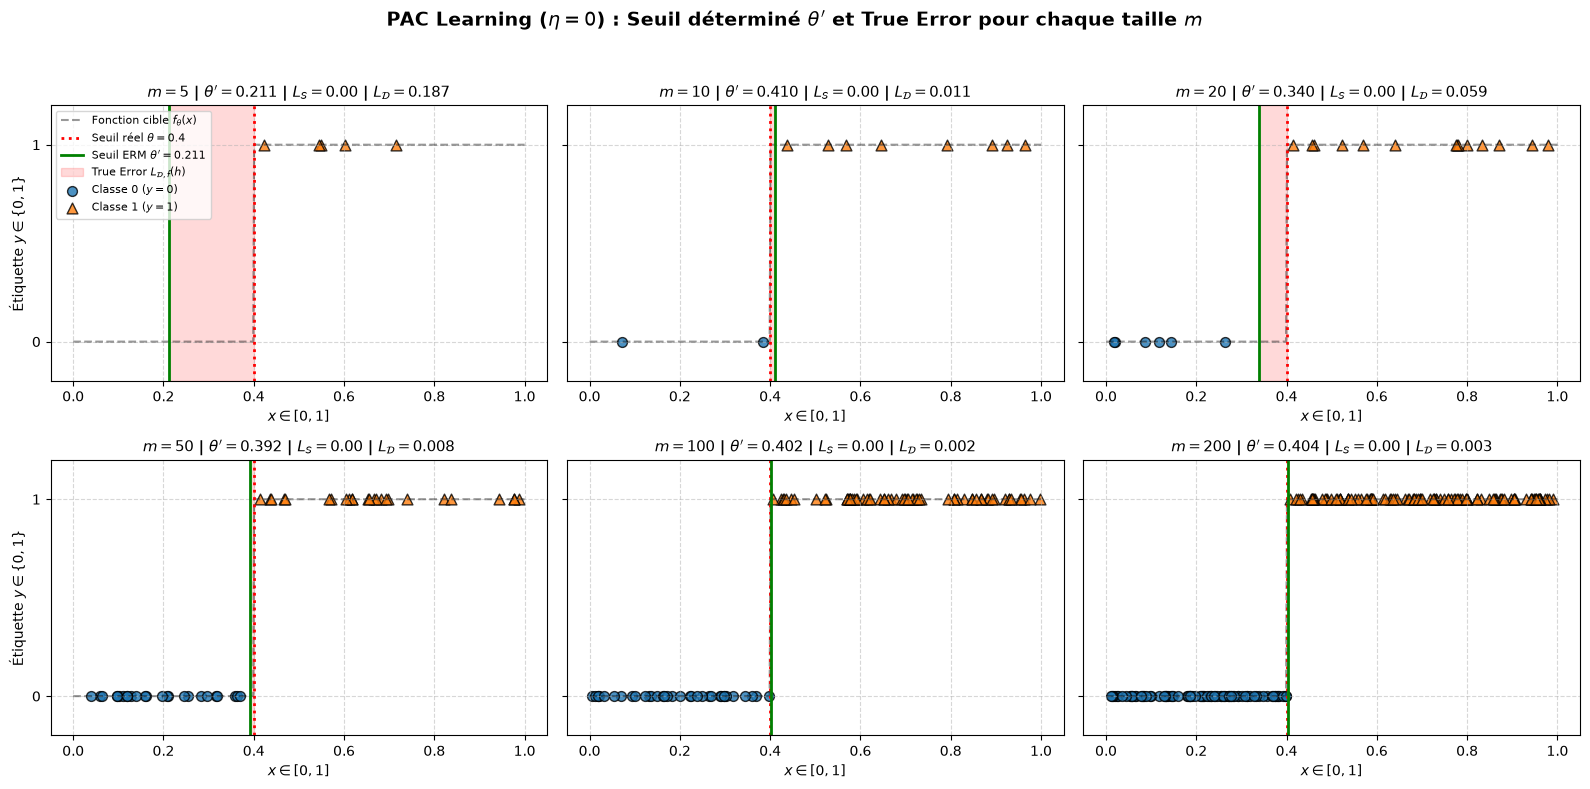

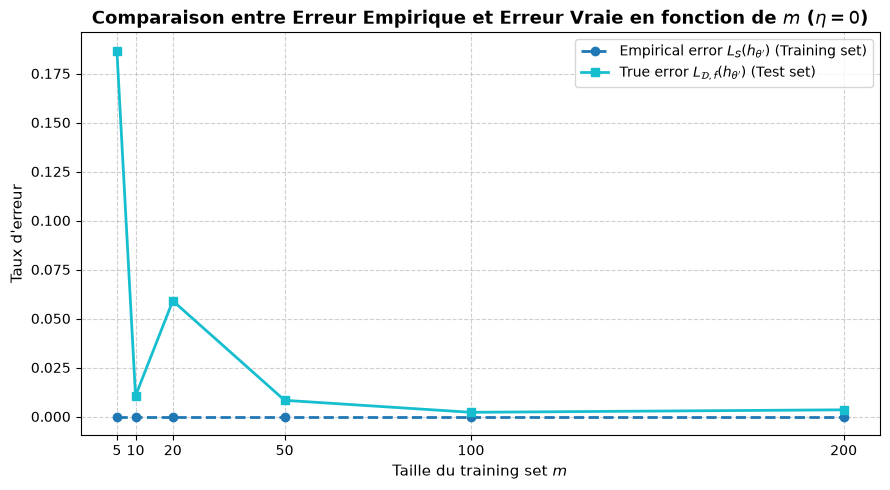

In [13]:
# Visualisation 1 : Comparaison entre le vrai seuil THETA et le seuil theta' trouvé par ERM
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
axes = axes.flatten()

x_grille = np.linspace(0, 1, 500)
y_courbe = fonction_cible(x_grille, THETA)

for idx, m in enumerate(m_tab):
  ax = axes[idx]
  x_ech, y_ech = datasets[m]
  theta_erm, err_emp, err_vraie = resultats_erm[m]

  # Tracé de la fonction cible f_theta(x)
  ax.plot(
      x_grille,
      y_courbe,
      color='black',
      linestyle='--',
      alpha=0.4,
      label=r'Fonction cible $f_\theta(x)$',
  )

  # Ligne verticale rouge : vrai seuil THETA
  ax.axvline(
      x=THETA,
      color='red',
      linestyle=':',
      linewidth=2,
      label=rf'Seuil réel $\theta={THETA}$',
  )

  # Ligne verticale verte : seuil déterminé par ERM
  ax.axvline(
      x=theta_erm,
      color='green',
      linestyle='-',
      linewidth=2,
      label=rf"Seuil ERM $\theta'={theta_erm:.3f}$",
  )

  # True error : zone rouge correspondant à la différence entre le vrai seuil et le seuil trouvé par l'ERM
  ax.axvspan(
      min(THETA, theta_erm),
      max(THETA, theta_erm),
      color='red',
      alpha=0.15,
      label=r'True Error $L_{\mathcal{D}, f}(h)$',
  )

  # Points du training set
  x_classe0 = x_ech[y_ech == 0]
  x_classe1 = x_ech[y_ech == 1]

  ax.scatter(
      x_classe0,
      np.zeros_like(x_classe0),
      color='tab:blue',
      marker='o',
      s=50,
      alpha=0.8,
      edgecolors='k',
      label=r'Classe 0 ($y=0$)',
  )
  ax.scatter(
      x_classe1,
      np.ones_like(x_classe1),
      color='tab:orange',
      marker='^',
      s=60,
      alpha=0.8,
      edgecolors='k',
      label=r'Classe 1 ($y=1$)',
  )

  ax.set_title(
      rf"$m = {m}$ | $\theta' = {theta_erm:.3f}$ | $L_S = {err_emp:.2f}$ |"
      rf' $L_\mathcal{{D}} = {err_vraie:.3f}$',
      fontsize=10.5,
      fontweight='bold',
  )
  ax.set_xlabel(r'$x \in [0, 1]$')
  if idx % 3 == 0:
    ax.set_ylabel(r'Étiquette $y \in \{0, 1\}$')
  ax.set_yticks([0, 1])
  ax.set_xlim(-0.05, 1.05)
  ax.set_ylim(-0.2, 1.2)
  ax.grid(True, linestyle='--', alpha=0.5)

  if idx == 0:
    ax.legend(loc='upper left', fontsize=8)

plt.suptitle(
    r'PAC Learning ($\eta = 0$) : Seuil déterminé $\theta^\prime$ et True Error'
    r' pour chaque taille $m$',
    fontsize=14,
    fontweight='bold',
)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# Visualisation 2 : Courbe comparant l'empirical error et la true error en fonction de m
erreurs_empiriques = [resultats_erm[m][1] for m in m_tab]
erreurs_vraies = [resultats_erm[m][2] for m in m_tab]

plt.figure(figsize=(9, 5))
plt.plot(
    m_tab,
    erreurs_empiriques,
    marker='o',
    linestyle='--',
    color='tab:blue',
    linewidth=2,
    label=r'Empirical error $L_S(h_{\theta^\prime})$ (Training set)',
)
plt.plot(
    m_tab,
    erreurs_vraies,
    marker='s',
    linestyle='-',
    color='tab:cyan',
    linewidth=2,
    label=r'True error $L_{\mathcal{D}, f}(h_{\theta^\prime})$ (Test set)',
)

plt.title(
    'Comparaison entre Erreur Empirique et Erreur Vraie en fonction de $m$'
    r' ($\eta = 0$)',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel(r"Taille du training set $m$", fontsize=11)
plt.ylabel('Taux d\'erreur', fontsize=11)
plt.xticks(m_tab)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

### Comparaison des erreurs
1. **Empirical error $L_S(h_{\theta'})$ toujours nulle :** Sur tous les training sets ($m$ allant de $5$ à $200$), l'empirical error vaut exactement $0$. C'est normal parce qu'on est dans le PAC Learning ($\eta = 0$), les données sont donc justes vu qu'il n'y a pas de bruit donc l'algorithme ERM trouve toujours un seuil ${\theta}'$ qui sépare bien les exemples $y=0$ et $y=1$ dans les training datasets.
2. **Différence avec la True error $L_{\mathcal{D}, f}(h_{\theta'})$ :** Contrairement à l'empirical error qui vaut 0, la true error calculée sur le grand test set indépendant (100 000 exemples) est strictement supérieure à $0$ lorsque ${\theta}' \neq \theta$. En effet, tous les nouveaux exemples du test set qui tombent dans la zone rouge entre $\theta$ et ${\theta}'$ sont mal classés par notre hypothèse.
3. **Effet de la taille d'échantillon $m$ sur la généralisation :** 
   * Quand $m$ est petit ($m=5, 10, 20$), l'écart entre l'empirical error ($0$) et la true error est souvent plutôt important car il y a peu de points autour de $\theta = 0.4$, donc le seuil appris ${\theta}'$ manque de précision.
   * Dès que $m$ devient grand ($m=100$ et $m=200$), la true error tend vers $0$, elle descend autour de $0.002 - 0.003$ et se rapproche de l'empirical error. Cela illustre bien le théorème vu en cours qu'avec la Realisability Assumption, la classe d'hypothèses de taille fini et un training dataset i.i.d (independant and identically distributed), si on a assez d'exemples $m$, alors l'ERM permet $L_S(h) \approx 0 \implies L_{\mathcal{D}, f}(h) \approx 0$.

## 4. Experimental Verification of PAC Learning
D'après la définition du PAC Learning vue en cours (CM1 & CM2), un algorithme apprend avec succès si, pour une précision $\epsilon \in (0, 1)$ et une probabilité d'échec $\delta \in (0, 1)$, dès que la taille d'échantillon $m$ est suffisamment grande, l'hypothèse $h_{\theta'}$ retournée par l'ERM vérifie :
$$\Pr(L_{\mathcal{D}, f}(h_{\theta'}) \le \epsilon) \ge 1 - \delta \quad$$

Dans cette question, on vérifie cette propriété expérimentalement :
* On fixe le seuil de précision à $\epsilon = 0.05$ (on tolère au maximum $5\%$ de True Error) et le seuil de confiance à $\delta = 0.05$ (on veut que la probabilité de dépasser $\epsilon$ soit inférieure à $5\%$).
* Pour chaque taille de training dataset $m \in \{5, 10, 20, 50, 100, 200\}$, on répète l'expérience $N = 500$ fois en générant à chaque fois un nouveau training dataset aléatoire.
* On estime la probabilité d'échec $\Pr(L_{\mathcal{D}, f}(h_{\theta'}) > \epsilon)$ par la proportion des $500$ répétitions où la True Error dépasse $\epsilon$.

In [6]:
# Paramètres choisis pour vérifier PAC Learning
EPSILON = 0.05  # Précision : erreur maximale tolérée (5%)
DELTA = 0.05  # Confiance voulue : probabilité d'échec maximale voulue (5%)
N_REPETITIONS = 500  # Nombre de répétitions de l'expérience pour chaque m

# Jeu de test indépendant (100 000 exemples) pour calculer rapidement la True Error à chaque répétition
m_test_pac = 100000
x_test_pac, y_test_pac = generer_dataset(m_test_pac, theta=THETA, eta=0.0)

probabilites_echec = []  # contient l'estimation de Pr(L(h) > epsilon) pour chaque m
moyennes_err_vraie = []  # contient aussi la True Error moyenne pour chaque m

print(
    f"Vérification expérimentale PAC (epsilon = {EPSILON}, delta = {DELTA},"
    f" {N_REPETITIONS} répétitions) :\n"
)

for m in m_tab:
  nb_echecs = 0  # Compteur du nombre de fois où L(h) > epsilon
  somme_err_vraie = 0.0

  for rep in range(N_REPETITIONS):
    # Nouveau training dataset aléatoire de taille m
    x_ech, y_ech = generer_dataset(m, theta=THETA, eta=0.0)

    # Application de l'algo ERM pour trouver le seuil optimal theta' qui minimise l'empirical error
    theta_erm, _ = algorithme_erm(x_ech, y_ech)

    # Calcul du true Error sur le test set
    err_vraie = calculer_erreur_vraie(x_test_pac, y_test_pac, theta_erm)
    somme_err_vraie += err_vraie

    # Vérification si l'hypothèse est une "Bad Hypothesis" lorsque L(h) > epsilon
    if err_vraie > EPSILON:
      nb_echecs += 1

  # Estimation de la probabilité Pr(L(h) > epsilon)
  proba_echec = nb_echecs / N_REPETITIONS
  err_vraie_moy = somme_err_vraie / N_REPETITIONS

  probabilites_echec.append(proba_echec)
  moyennes_err_vraie.append(err_vraie_moy)

  if proba_echec <= DELTA:
    garantie_pac = "OUI (<= delta)"
  else:
    garantie_pac = "NON (> delta)"

  print(
      f"m = {m:3d} | Pr(L(h) > {EPSILON}) = {proba_echec:.4f} | "
      f"True Error moyenne = {err_vraie_moy:.4f} | Garantie PAC respectée :"
      f" {garantie_pac}"
  )

Vérification expérimentale PAC (epsilon = 0.05, delta = 0.05, 500 répétitions) :

m =   5 | Pr(L(h) > 0.05) = 0.5700 | True Error moyenne = 0.0715 | Garantie PAC respectée : NON (> delta)
m =  10 | Pr(L(h) > 0.05) = 0.3380 | True Error moyenne = 0.0448 | Garantie PAC respectée : NON (> delta)
m =  20 | Pr(L(h) > 0.05) = 0.1040 | True Error moyenne = 0.0236 | Garantie PAC respectée : NON (> delta)
m =  50 | Pr(L(h) > 0.05) = 0.0040 | True Error moyenne = 0.0091 | Garantie PAC respectée : OUI (<= delta)
m = 100 | Pr(L(h) > 0.05) = 0.0000 | True Error moyenne = 0.0049 | Garantie PAC respectée : OUI (<= delta)
m = 200 | Pr(L(h) > 0.05) = 0.0000 | True Error moyenne = 0.0025 | Garantie PAC respectée : OUI (<= delta)


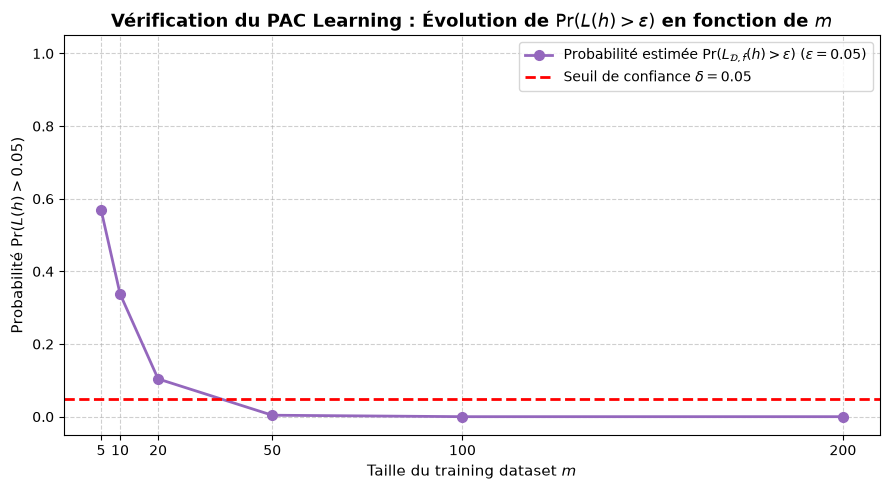

In [14]:
# Visualisation de l'évolution de la probabilité Pr(L(h) > epsilon) lorsque m augmente
plt.figure(figsize=(9, 5))

# Courbe de la probabilité estimée Pr(L(h) > epsilon)
plt.plot(
    m_tab,
    probabilites_echec,
    marker='o',
    linestyle='-',
    color='tab:purple',
    linewidth=2,
    markersize=7,
    label=rf'Probabilité estimée $\Pr(L_{{\mathcal{{D}}, f}}(h) > \epsilon)$ ($\epsilon={EPSILON}$)',
)

# Ligne horizontale représentant la confiance voulue delta, si la probabilité Pr(L(h) > epsilon) est en dessous, alors le learner a appris avec succès
plt.axhline(
    y=DELTA,
    color='red',
    linestyle='--',
    linewidth=2,
    label=rf'Seuil de confiance $\delta = {DELTA}$',
)

plt.title(
    r'Vérification du PAC Learning : Évolution de $\Pr(L(h) > \epsilon)$ en'
    r' fonction de $m$',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel(r'Taille du training dataset $m$', fontsize=11)
plt.ylabel(rf'Probabilité $\Pr(L(h) > {EPSILON})$', fontsize=11)
plt.xticks(m_tab)
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

### Interprétation de la vérification expérimentale du PAC Learning
1. **$\Pr(L(h) > \epsilon)$ diminue quand $m$ augmente :** Sur le graphique, on voit que la probabilité d'obtenir une "mauvaise hypothèse" (c'est-à-dire une hypothèse dont la True Error dépasse $\epsilon = 0.05$) diminue très rapidement lorsque le nombre d'exemples $m$ du Sample augmente :
   * Pour $m = 5$ et $m = 10$, la probabilité d'échec est très élevée parce qu'il n'y a pas assez de points pour voir précisément le vrai seuil $\theta = 0.4$.
   * À partir de $m = 100$ et $m = 200$, la probabilité $\Pr(L(h) > \epsilon)$ passe sous les pointillés rouges $\delta = 0.05$ et tombe même à $0.0000$ : l'ERM a bien trouvé une hypothèse assurée par les garanties PAC.
2. **Lien avec la Sample Complexity vue en cours :** 
   * Cela confirme expérimentalement que l'ERM est $P$robably $A$pproximately $C$orrect (PAC) : à partir d'une certaine taille d'échantillon $m \ge m_{\mathcal{H}}(\epsilon, \delta)$ (ici entre $m=50$ et $m=100$), la garantie PAC $\Pr(L_{\mathcal{D}, f}(h) \le \epsilon) \ge 1 - \delta$ est respectée.
   * On remarque aussi que la taille d'échantillon nécessaire en pratique dans l'expérience (entre 60 et 100) est bien plus petite que la borne supérieure théorique vue en cours $m \ge \frac{1}{\epsilon}(\ln|\mathcal{H}| + \ln\frac{1}{\delta})$ (qui donnerait environ $m \ge 198$ avec $|\mathcal{H}|=1001$), ce qui confirme que la borne selon la formule du théorème est bien une borne supérieure dans le pire des cas.

## 5. From PAC to Agnostic PAC
L'hypothèse de réalisabilité (Realizability Assumption) est rarement respectée dans la vie réelle à cause du bruit dans les données (labels incorrects ou bruités). On est dans ce cas dans le cadre Agnostic PAC (APAC) Learning :
* Chaque étiquette $y$ est maintenant inversée indépendamment avec une probabilité $\eta$. On choisit ici un taux de bruit **$\eta = 0.20$** ($20\%$ d'étiquettes inversées).
* Aucune hypothèse ne peut atteindre une erreur vraie nulle. Le meilleur classifieur possible (le classifieur optimal de Bayes qui utilise le vrai seuil $\theta = 0.4$) commet lui-même une erreur incompressible égale au taux de bruit :
$$\min_{h' \in \mathcal{H}} L_{\mathcal{D}}(h') = L_{\mathcal{D}}(h_\theta) = \eta = 0.20$$

En effet, d'après the Bayes optimal predictor, lorsque $x > \theta$ : l'étiquette reste de 1 dans 80% des cas, de 0 dans 20% des cas (lorsque $\eta = 0.20$). Comme $80% \ge 50%$, l'étiquette la plus probable est 1, il prédit alors toujours 1. Son taux d'erreur est donc de 20% parce qu'il se trompe 20% du temps.
De même lorsque $x \le \theta$, l'étiquette est de 0 80% du temps, l'étiquette la plus probable est donc 0 mais il se trompe 20% du temps.
* Objectif Agnostic PAC : Le learner cherche à s'approcher de moins de $\epsilon$ de cette meilleure erreur possible :
$$\Pr\left(L_{\mathcal{D}}(h_{\theta'}) \le \min_{h' \in \mathcal{H}} L_{\mathcal{D}}(h') + \epsilon\right) \ge 1 - \delta \quad \Longleftrightarrow \quad \Pr\left(L_{\mathcal{D}}(h_{\theta'}) > \eta + \epsilon\right) \le \delta$$

On répète maintenant toutes les expériences précédentes avec $\eta = 0.20$.

In [8]:
# Fixer la graine pour reproduire les expériences avec les mêmes résultats
np.random.seed(0)

# Paramètre du bruit dans le cadre APAC
ETA = 0.20  # 20% de probabilité d'inverser chaque étiquette

# Génération des training datasets bruités pour chaque taille m
datasets_apac = {}
for m in m_tab:
  datasets_apac[m] = generer_dataset(m, theta=THETA, eta=ETA)

# Génération d'un grand test set indépendant bruité (100 000 exemples)
m_test = 100000
x_test_apac, y_test_apac = generer_dataset(m_test, theta=THETA, eta=ETA)

# Application de l'ERM et calcul de l'Empirical Error et de la True Error
resultats_erm_apac = {}

print(
    f"Évaluation de l'ERM en Agnostic PAC (Vrai THETA = {THETA}, Bruit ETA ="
    f" {ETA}) :\n"
)
for m in m_tab:
  x_ech, y_ech = datasets_apac[m]
  theta_erm, err_emp = algorithme_erm(x_ech, y_ech)
  err_vraie = calculer_erreur_vraie(x_test_apac, y_test_apac, theta_erm)
  resultats_erm_apac[m] = (theta_erm, err_emp, err_vraie)

  print(
      f"m = {m:3d} | Seuil trouvé theta' = {theta_erm:.4f} | "
      f"Erreur empirique L_S(h) = {err_emp:.4f} | "
      f"True Error L_D(h) = {err_vraie:.4f} (Optimum théorique = {ETA:.4f})"
  )

Évaluation de l'ERM en Agnostic PAC (Vrai THETA = 0.4, Bruit ETA = 0.2) :

m =   5 | Seuil trouvé theta' = 0.2115 | Erreur empirique L_S(h) = 0.0000 | True Error L_D(h) = 0.3109 (Optimum théorique = 0.2000)
m =  10 | Seuil trouvé theta' = 0.0100 | Erreur empirique L_S(h) = 0.1000 | True Error L_D(h) = 0.4320 (Optimum théorique = 0.2000)
m =  20 | Seuil trouvé theta' = 0.3375 | Erreur empirique L_S(h) = 0.3000 | True Error L_D(h) = 0.2341 (Optimum théorique = 0.2000)
m =  50 | Seuil trouvé theta' = 0.4055 | Erreur empirique L_S(h) = 0.1800 | True Error L_D(h) = 0.2010 (Optimum théorique = 0.2000)
m = 100 | Seuil trouvé theta' = 0.4043 | Erreur empirique L_S(h) = 0.2200 | True Error L_D(h) = 0.2002 (Optimum théorique = 0.2000)
m = 200 | Seuil trouvé theta' = 0.4035 | Erreur empirique L_S(h) = 0.2200 | True Error L_D(h) = 0.1995 (Optimum théorique = 0.2000)


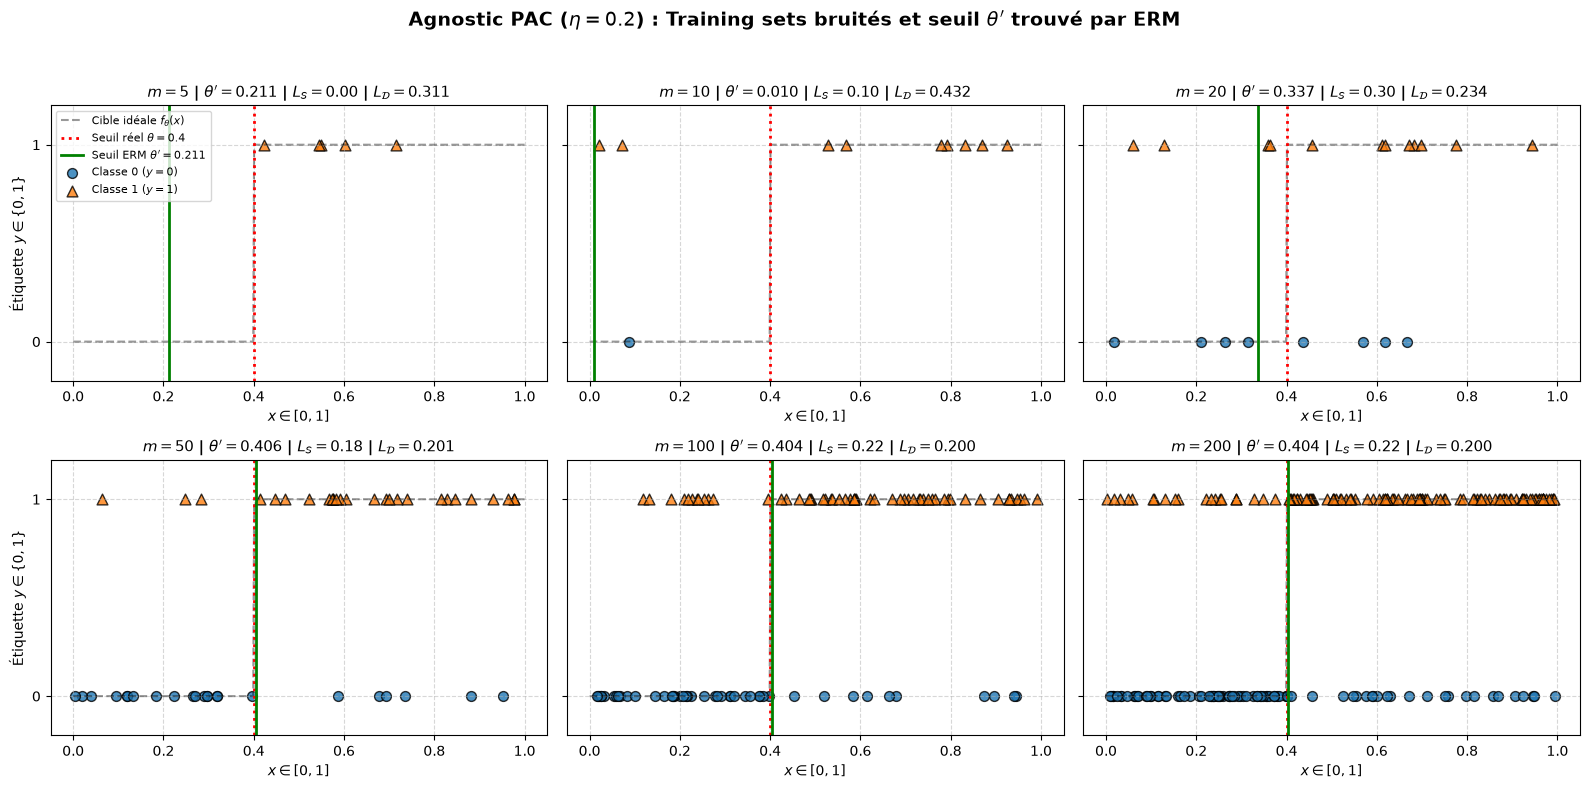

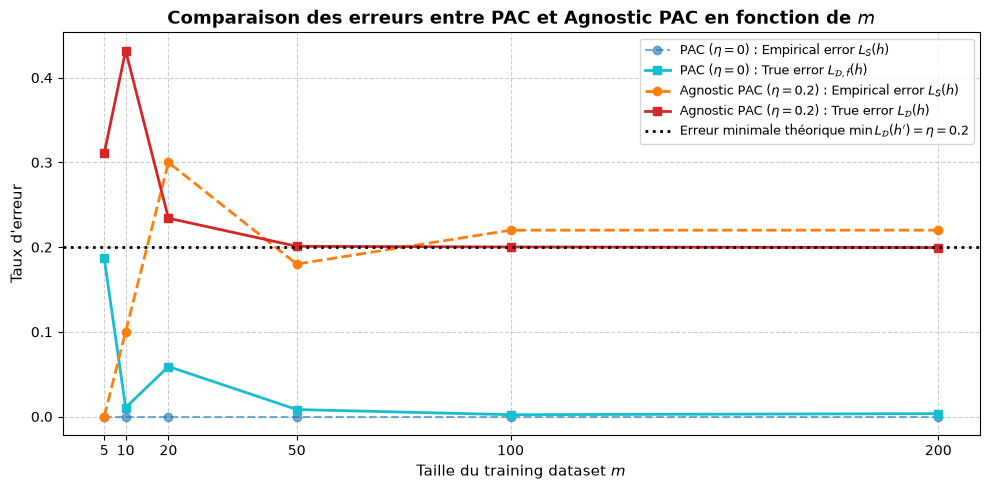

In [15]:
# Visualisation 1 : Training datasets bruités et seuil theta' trouvé par ERM en Agnostic PAC
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
axes = axes.flatten()

x_grille = np.linspace(0, 1, 500)
y_courbe = fonction_cible(x_grille, THETA)

for idx, m in enumerate(m_tab):
  ax = axes[idx]
  x_ech, y_ech = datasets_apac[m]
  theta_erm, err_emp, err_vraie = resultats_erm_apac[m]

  # Tracé de la fonction cible sans bruit f_theta(x)
  ax.plot(
      x_grille,
      y_courbe,
      color='black',
      linestyle='--',
      alpha=0.4,
      label=r'Cible idéale $f_\theta(x)$',
  )

  # Ligne verticale rouge : vrai seuil THETA
  ax.axvline(
      x=THETA,
      color='red',
      linestyle=':',
      linewidth=2,
      label=rf'Seuil réel $\theta={THETA}$',
  )

  # Ligne verticale verte : seuil theta' déterminé par ERM
  ax.axvline(
      x=theta_erm,
      color='green',
      linestyle='-',
      linewidth=2,
      label=rf"Seuil ERM $\theta'={theta_erm:.3f}$",
  )

  # Points du training dataset bruité
  x_classe0 = x_ech[y_ech == 0]
  x_classe1 = x_ech[y_ech == 1]

  ax.scatter(
      x_classe0,
      np.zeros_like(x_classe0),
      color='tab:blue',
      marker='o',
      s=50,
      alpha=0.8,
      edgecolors='k',
      label=r'Classe 0 ($y=0$)',
  )
  ax.scatter(
      x_classe1,
      np.ones_like(x_classe1),
      color='tab:orange',
      marker='^',
      s=60,
      alpha=0.8,
      edgecolors='k',
      label=r'Classe 1 ($y=1$)',
  )

  ax.set_title(
      rf"$m = {m}$ | $\theta' = {theta_erm:.3f}$ | $L_S = {err_emp:.2f}$ |"
      rf' $L_\mathcal{{D}} = {err_vraie:.3f}$',
      fontsize=10.5,
      fontweight='bold',
  )
  ax.set_xlabel(r'$x \in [0, 1]$')
  if idx % 3 == 0:
    ax.set_ylabel(r'Étiquette $y \in \{0, 1\}$')
  ax.set_yticks([0, 1])
  ax.set_xlim(-0.05, 1.05)
  ax.set_ylim(-0.2, 1.2)
  ax.grid(True, linestyle='--', alpha=0.5)

  if idx == 0:
    ax.legend(loc='upper left', fontsize=8)

plt.suptitle(
    rf'Agnostic PAC ($\eta = {ETA}$) : Training sets bruités et seuil'
    r' $\theta^\prime$ trouvé par ERM',
    fontsize=14,
    fontweight='bold',
)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# Visualisation 2 : Comparaison de l'Empirical Error et de la True Error (PAC vs Agnostic PAC)
err_emp_apac = [resultats_erm_apac[m][1] for m in m_tab]
err_vraie_apac = [resultats_erm_apac[m][2] for m in m_tab]

plt.figure(figsize=(10, 5))
plt.plot(
    m_tab,
    erreurs_empiriques,
    marker='o',
    linestyle='--',
    color='tab:blue',
    alpha=0.6,
    label=r'PAC ($\eta=0$) : Empirical error $L_S(h)$',
)
plt.plot(
    m_tab,
    erreurs_vraies,
    marker='s',
    linestyle='-',
    color='tab:cyan',
    linewidth=2,
    label=r'PAC ($\eta=0$) : True error $L_{\mathcal{D}, f}(h)$',
)

plt.plot(
    m_tab,
    err_emp_apac,
    marker='o',
    linestyle='--',
    color='tab:orange',
    linewidth=2,
    label=rf'Agnostic PAC ($\eta={ETA}$) : Empirical error $L_S(h)$',
)
plt.plot(
    m_tab,
    err_vraie_apac,
    marker='s',
    linestyle='-',
    color='tab:red',
    linewidth=2,
    label=rf'Agnostic PAC ($\eta={ETA}$) : True error $L_\mathcal{{D}}(h)$',
)

plt.axhline(
    y=ETA,
    color='black',
    linestyle=':',
    linewidth=2,
    label=rf'Erreur minimale théorique $\min L_\mathcal{{D}}(h^\prime) = \eta = {ETA}$',
)

plt.title(
    'Comparaison des erreurs entre PAC et Agnostic PAC en fonction'
    ' de $m$',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel(r'Taille du training dataset $m$', fontsize=11)
plt.ylabel("Taux d'erreur", fontsize=11)
plt.xticks(m_tab)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

### Interprétation des training sets bruités et des erreurs en Agnostic PAC ($\eta = 0.20$)

**1. Apparition de faux exemples (Visualisation 1) :**
   * Contrairement au cadre PAC réalisable ($\eta = 0$), on observe maintenant des erreurs d'étiquettes sur nos graphiques : il y a des triangles oranges ($y=1$) situés à gauche du vrai seuil rouge ($\theta = 0.4$) et des ronds bleus ($y=0$) situés à droite de $\theta = 0.4$, qui ne respectent pas la fonction cible alors que ce n'était pas le cas dans le PAC Learning. Cela est donc logique étant donné que la fonction cible "n'existe pas" dans l'APAC.
   * L'hypothèse de réalisabilité n'est donc plus respectée : les deux classes se chevauchent et aucune hypothèse de notre classe $\mathcal{H}$ ne peut séparer parfaitement les points sans faire d'erreur.

**2. Comportement du seuil $\theta'$ trouvé par l'ERM :**
   * Pour de petites tailles d'échantillons ($m = 5$ ou $m = 10$), quelques points bruités suffisent pour que l'algorithme ERM se trompe, ce qui fait décaler la ligne verte ($\theta'$) de seuil trouvé par l'ERM assez loin de la ligne rouge ($\theta = 0.4$).
   * Cependant, quand $m$ devient grand ($m = 100$ et $m = 200$), le nombre d'exemples corrects ($80\%$) l'emporte largement sur les exemples inversés ($20\%$). L'ERM n'est plus piégé le bruit et place son seuil $\theta'$ quasiment au même endroit que le vrai seuil ($\theta' \approx 0.404$ pour $m=100$ et $\theta' = 0.4035$ pour $m=200$).

**3. Comparaison de l'Empirical Error et de la True Error (Visualisation 2) :**
   * **Empirical error $L_S(h_{\theta'})$ :** Alors qu'elle valait toujours $0$ en PAC Learning (courbe bleue en pointillés), l'erreur empirique en Agnostic PAC (courbe orange) ne peut plus rester à $0$ lorsque $m$ augmente. Elle grimpe et se stabilise autour de $0.22$ (très proche du taux de bruit $\eta = 0.20$).
   * **True error $L_{\mathcal{D}}(h_{\theta'})$ :** En PAC Learning, la True error tendait vers $0$. En Agnostic PAC (courbe rouge), la True Error diminue quand $m$ augmente mais bloque sur la limite inférieure égale au taux de bruit $\min_{h' \in \mathcal{H}} L_{\mathcal{D}}(h') = \eta = 0.20$ (ligne horizontale noire en pointillés). En effet, même avec le meilleur seuil possible ($\theta = 0.4$), le classifieur se trompera toujours sur les $20\%$ d'étiquettes inversées aléatoirement.
   * On voit aussi que pour $m=200$, on observe une True Error de $0.1995$, très légèrement en dessous de $0.2000$. Cet écart très petit s'explique par le côté aléatoire du tirage de notre test set fini de $100\,000$ exemples, dans lequel la proportion d'étiquettes inversées est tombée par hasard légèrement en dessous de $20\%$.

In [10]:
# Vérification expérimentale d'Agnostic PAC sur 500 répétitions
m_test_rep = 100000
x_test_rep, y_test_rep = generer_dataset(m_test_rep, theta=THETA, eta=ETA)

probabilites_echec_apac = []  # Estimation de Pr(L_D(h) > eta + epsilon)
probabilites_echec_absolu = (
    []
)  
# Estimation de Pr(L_D(h) > epsilon) pour montrer pourquoi la définition PAC échoue
moyennes_err_emp_apac = []
moyennes_err_vraie_apac = []

print(
    f"Vérification expérimentale Agnostic PAC (eta = {ETA}, epsilon ="
    f" {EPSILON}, delta = {DELTA}, {N_REPETITIONS} répétitions) :\n"
)

for m in m_tab:
  nb_echecs_apac = 0  # Compteur pour L_D(h) > eta + epsilon
  nb_echecs_absolu = 0  # Compteur pour L_D(h) > epsilon
  somme_emp = 0.0
  somme_vraie = 0.0

  for rep in range(N_REPETITIONS):
    x_ech, y_ech = generer_dataset(m, theta=THETA, eta=ETA)
    theta_erm, err_emp = algorithme_erm(x_ech, y_ech)
    err_vraie = calculer_erreur_vraie(x_test_rep, y_test_rep, theta_erm)

    somme_emp += err_emp
    somme_vraie += err_vraie

    # Condition d'échec Agnostic PAC : L_D(h) > min L_D(h') + epsilon = eta + epsilon
    if err_vraie > (ETA + EPSILON):
      nb_echecs_apac += 1

    # Ancienne condition PAC réalisable pour l'échec : L_D(h) > epsilon
    if err_vraie > EPSILON:
      nb_echecs_absolu += 1

  proba_apac = nb_echecs_apac / N_REPETITIONS
  proba_absolu = nb_echecs_absolu / N_REPETITIONS
  moy_emp = somme_emp / N_REPETITIONS
  moy_vraie = somme_vraie / N_REPETITIONS

  probabilites_echec_apac.append(proba_apac)
  probabilites_echec_absolu.append(proba_absolu)
  moyennes_err_emp_apac.append(moy_emp)
  moyennes_err_vraie_apac.append(moy_vraie)


  if proba_apac <= DELTA:
    garantie_apac = "OUI (<= delta)"
  else:
    garantie_apac = "NON (> delta)"

  print(
      f"m = {m:3d} | L_S moy = {moy_emp:.4f} | L_D moy = {moy_vraie:.4f} | "
      f"Pr(L_D(h) > eta + eps) = {proba_apac:.4f} | Garantie APAC :"
      f" {garantie_apac}"
  )

Vérification expérimentale Agnostic PAC (eta = 0.2, epsilon = 0.05, delta = 0.05, 500 répétitions) :

m =   5 | L_S moy = 0.1104 | L_D moy = 0.2944 | Pr(L_D(h) > eta + eps) = 0.6380 | Garantie APAC : NON (> delta)
m =  10 | L_S moy = 0.1400 | L_D moy = 0.2727 | Pr(L_D(h) > eta + eps) = 0.5180 | Garantie APAC : NON (> delta)
m =  20 | L_S moy = 0.1745 | L_D moy = 0.2530 | Pr(L_D(h) > eta + eps) = 0.3500 | Garantie APAC : NON (> delta)
m =  50 | L_S moy = 0.1833 | L_D moy = 0.2258 | Pr(L_D(h) > eta + eps) = 0.1560 | Garantie APAC : NON (> delta)
m = 100 | L_S moy = 0.1963 | L_D moy = 0.2135 | Pr(L_D(h) > eta + eps) = 0.0320 | Garantie APAC : OUI (<= delta)
m = 200 | L_S moy = 0.1950 | L_D moy = 0.2068 | Pr(L_D(h) > eta + eps) = 0.0040 | Garantie APAC : OUI (<= delta)


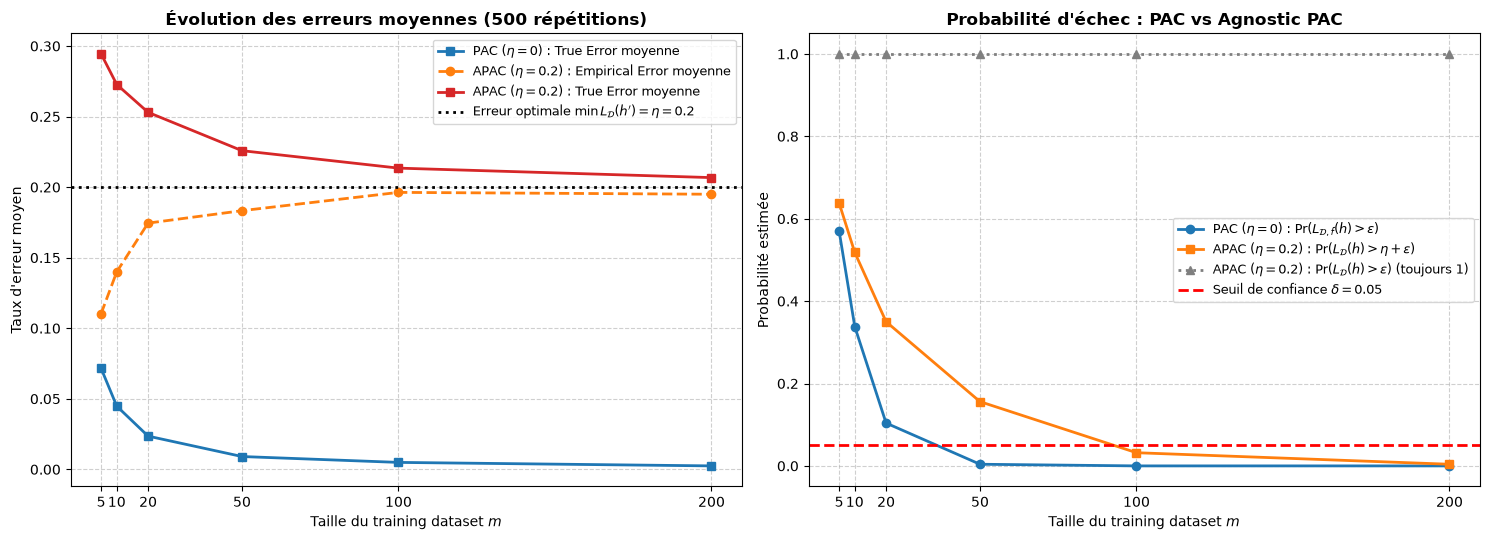

In [11]:
# Visualisation comparative finale sur les 500 répétitions
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Graphique de gauche : Moyennes des erreurs sur 500 répétitions
ax1.plot(
    m_tab,
    moyennes_err_vraie,
    marker='s',
    linestyle='-',
    color='tab:blue',
    linewidth=2,
    label=r'PAC ($\eta=0$) : True Error moyenne',
)
ax1.plot(
    m_tab,
    moyennes_err_emp_apac,
    marker='o',
    linestyle='--',
    color='tab:orange',
    linewidth=2,
    label=rf'APAC ($\eta={ETA}$) : Empirical Error moyenne',
)
ax1.plot(
    m_tab,
    moyennes_err_vraie_apac,
    marker='s',
    linestyle='-',
    color='tab:red',
    linewidth=2,
    label=rf'APAC ($\eta={ETA}$) : True Error moyenne',
)
ax1.axhline(
    y=ETA,
    color='black',
    linestyle=':',
    linewidth=2,
    label=rf'Erreur optimale $\min L_\mathcal{{D}}(h^\prime) = \eta = {ETA}$',
)

ax1.set_title(
    'Évolution des erreurs moyennes (500 répétitions)',
    fontsize=12,
    fontweight='bold',
)
ax1.set_xlabel(r'Taille du training dataset $m$')
ax1.set_ylabel("Taux d'erreur moyen")
ax1.set_xticks(m_tab)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(fontsize=9)

# Graphique de droite : Probabilités d'échec PAC vs APAC
ax2.plot(
    m_tab,
    probabilites_echec,
    marker='o',
    linestyle='-',
    color='tab:blue',
    linewidth=2,
    label=r'PAC ($\eta=0$) : $\Pr(L_{\mathcal{D}, f}(h) > \epsilon)$',
)
ax2.plot(
    m_tab,
    probabilites_echec_apac,
    marker='s',
    linestyle='-',
    color='tab:orange',
    linewidth=2,
    label=rf'APAC ($\eta={ETA}$) : $\Pr(L_\mathcal{{D}}(h) > \eta + \epsilon)$',
)
ax2.plot(
    m_tab,
    probabilites_echec_absolu,
    marker='^',
    linestyle=':',
    color='tab:gray',
    linewidth=2,
    label=rf'APAC ($\eta={ETA}$) : $\Pr(L_\mathcal{{D}}(h) > \epsilon)$ (toujours 1)',
)
ax2.axhline(
    y=DELTA,
    color='red',
    linestyle='--',
    linewidth=2,
    label=rf'Seuil de confiance $\delta = {DELTA}$',
)

ax2.set_title(
    "Probabilité d'échec : PAC vs Agnostic PAC", fontsize=12, fontweight='bold'
)
ax2.set_xlabel(r'Taille du training dataset $m$')
ax2.set_ylabel('Probabilité estimée')
ax2.set_xticks(m_tab)
ax2.set_ylim(-0.05, 1.05)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()

### Discussion et comparaison entre les cadres PAC et Agnostic PAC

#### 1. Can the empirical error still reach zero ?
* Non, l'empirical error ne peut pas atteindre 0 dans l'Agnostic PAC, parce qu'il y a 20% de risque que les étiquettes soient inversées aléatoirement. L'ERM en étudiant ces training datasets va alors avoir du mal à déterminer le seuil sans commettre une erreur. Alors que dans le PAC, l'empirical error est toujours de 0 parce que l'hypothèse de réalisabilité est présente, donc la fonction cible existe et il n'y a donc aucune erreur sur le training dataset. L'ERM ne se trompe donc jamais sur le training dataset dans le cadre PAC.
* On voit qu'au début l'empirical error de l'APAC est petite et très éloignée du true error avant d'augmenter et de rapprocher de 0.2 (et du true error), cela s'explique par le fait qu'on n'a pas beaucoup d'exemples et que l'empirical error n'est pas assez proche du true error lorsqu'on n'a pas assez d'exemples.

#### 2. Does increasing the number of training examples still improve the generalization performance ?
* Oui, augmenter le nombre d'exemples d'entrainement améliore la performance de la généralisation. Bien que la True Error ne puisse jamais descendre en dessous de $\eta = 0.20$, augmenter $m$ améliore nettement la performance de généralisation de l'APAC :
  * Pour $m = 5$, la True Error moyenne est d'environ $0.25$ car le seuil ${\theta}'$ est mal estimé par l'ERM parce qu'il y a très peu d'exemples.
  * Lorsque $m$ passe à $100$ puis $200$, le seuil appris ${\theta}'$ se rapproche de plus en plus du vrai seuil $\theta = 0.4$, et la True Error moyenne diminue progressivement pour converger vers l'erreur optimale $\min_{h' \in \mathcal{H}} L_{\mathcal{D}}(h') = \eta = 0.20$.
  * De même, en ouverture sur le chapitre "Learning via Uniform Convergence", l'écart (Generalization gap) entre l'empirical error et la true error $|L_{\mathcal{D}}(h) - L_S(h)|$ tend vers $0$ quand $m$ augmente. Selon le generalization gap toléré, on peut profiter des propriétés d'un sample $S$ $\epsilon-representative$ lié à l'Uniform Convergence pour déterminer le nombre d'exemples m nécessaire.

#### 3. How do your observations relate to the PAC and Agnostic PAC learning frameworks ?
* Si on gardait l'exigence du PAC Learning $\Pr(L_{\mathcal{D}}(h) > \epsilon) \le \delta$ avec $\epsilon = 0.05 < \eta = 0.20$ en gardant donc l'inversion des étiquettes, la probabilité d'échec resterait bloquée à $1$ ($100\%$ d'échec, courbe grise sur le graphique de droite), car aucune hypothèse ne peut faire mieux que $\eta = 0.20$. En effet, on souhaite moins de 5% d'erreur, mais avec les inversions, les training datasets ont 20% d'étiquettes fausses et la distribution contient aussi 20% d'étiquettes inversées et donc fausses. L'ERM ne peut donc donner une hypothèse qui donne une true error en dessous de 20% étant donné que même la fonction cible idéale subit ces 20% des étiquettes fausses.
* Par contre, dans le cadre Agnostic PAC, on compare notre hypothèse apprise $h_{\theta'}$ avec la meilleure hypothèse de la classe $\mathcal{H}$ (qui a une erreur $\min_{h' \in \mathcal{H}} L_{\mathcal{D}}(h') = \eta = 0.20$). La probabilité d'échec $\Pr(L_{\mathcal{D}}(h_{\theta'}) > \eta + \epsilon)$ (courbe verte) décroît bien vers $0$ et passe sous le seuil $\delta = 0.05$ lorsque $m$ augmente (autour de $m = 100 - 200$).
* On observe également que la Sample Complexity (le nombre d'exemples nécessaires pour passer sous $\delta = 0.05$) est plus élevée en Agnostic PAC ($m \approx 100$) qu'en PAC réalisable ($m \approx 50$), car le bruit rend l'estimation du seuil optimal plus difficile. Cela demande davantage de données pour que les fausses étiquettes n'aient plus d'influence.

---

## Conclusion
Cette expérience a permis de voir expérimentalement les différences entre l'apprentissage PAC et  Agnostic PAC à l'aide de l'algorithme ERM sur des classifieurs à seuil. On a pu voir l'intérêt de l'APAC lorsqu'il y a du bruit : cela permet de garder l'hypothèse donnée par l'ERM viable, là où dans le cadre PAC son hypothèse serait rejetée parce que la probabilité d'échec serait trop élevé.

---
Note : Ce travail a été réalisé avec l'appui de l'IA générative Gemini comme outil d'assistance (notamment pour l'affichage graphique et approfondir les notions vues en cours).